# Retinal Vessel Mask Sensitivity Analysis

Controlled perturbation experiments on the 45-image HRF retinal vessel segmentation dataset.

In [1]:
from pathlib import Path
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from retina_sensitivity.data import ensure_hrf_data, load_hrf_sample
from retina_sensitivity.experiment import run_experiment
from retina_sensitivity.perturbations import make_perturbations

DATA_ROOT = ensure_hrf_data(ROOT)
RESULTS = ROOT / "results"

## Inspect a real HRF image and its expert annotation

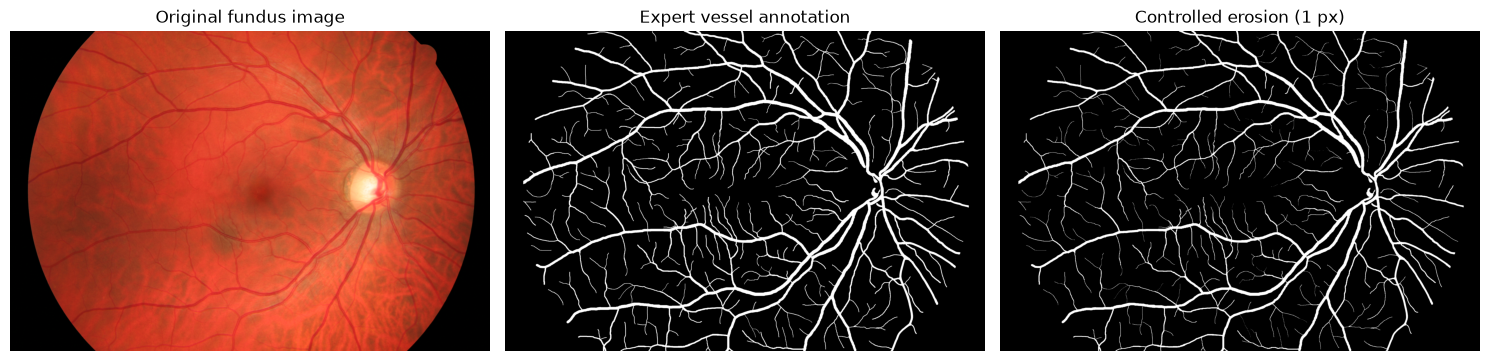

In [2]:
sample = load_hrf_sample(DATA_ROOT, "01_h")
variants = make_perturbations(sample.vessel_mask, sample.fov_mask)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample.image)
axes[0].set_title("Original fundus image")
axes[1].imshow(sample.vessel_mask, cmap="gray")
axes[1].set_title("Expert vessel annotation")
axes[2].imshow(variants["erosion_r1"], cmap="gray")
axes[2].set_title("Controlled erosion (1 px)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

## Run the sensitivity experiment across the HRF dataset

In [4]:
SAMPLE_LIMIT = 3
per_image, summary = run_experiment(DATA_ROOT, RESULTS, sample_limit=SAMPLE_LIMIT)
summary

,condition,images,mean_dice,mean_iou,vessel_area_pixels_change_pct,vessel_area_fraction_change_pct,skeleton_pixel_count_change_pct,skeleton_component_count_change_pct,endpoint_pixel_count_change_pct,junction_cluster_count_change_pct
0,original,3,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,erosion_r1,3,0.875824,0.779658,-22.034222,-22.034222,-14.223612,47995.238095,691.674934,-23.744840
2,erosion_r2,3,0.749954,0.600877,-39.912304,-39.912304,-33.137967,22893.650794,529.862765,-44.273055
3,dilation_r1,3,0.898647,0.816283,22.617000,22.617000,-0.494187,-30.158730,-3.700397,1.005143
4,dilation_r2,3,0.817414,0.691950,44.890799,44.890799,-0.810508,-50.793651,-4.272487,3.273862


In [3]:
SAMPLE_LIMIT = int(os.environ.get("RETINA_SAMPLE_LIMIT", "0")) or None
per_image, summary = run_experiment(DATA_ROOT, RESULTS, sample_limit=SAMPLE_LIMIT)
summary

KeyboardInterrupt: 

## Compare mask overlap and feature sensitivity

,dataset,image_id,group,condition,dice_vs_original,iou_vs_original,vessel_area_pixels,vessel_area_fraction,skeleton_pixel_count,skeleton_component_count,endpoint_pixel_count,junction_cluster_count,vessel_area_pixels_change_pct,vessel_area_fraction_change_pct,skeleton_pixel_count_change_pct,skeleton_component_count_change_pct,endpoint_pixel_count_change_pct,junction_cluster_count_change_pct
0,HRF,01_dr,diabetic_retinopathy,original,1.000000,1.000000,415917.0,0.060165,53071.0,7.0,144.0,211.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,HRF,01_dr,diabetic_retinopathy,erosion_r1,0.864074,0.760678,316379.0,0.045766,41992.0,1733.0,1701.0,141.0,-23.932179,-23.932179,-20.875808,24657.142857,1081.250000,-33.175355
2,HRF,01_dr,diabetic_retinopathy,erosion_r2,0.731111,0.576182,239644.0,0.034666,32078.0,775.0,756.0,94.0,-42.381773,-42.381773,-39.556443,10971.428571,425.000000,-55.450237
3,HRF,01_dr,diabetic_retinopathy,dilation_r1,0.888601,0.799534,520199.0,0.075249,52802.0,3.0,133.0,208.0,25.072791,25.072791,-0.506868,-57.142857,-7.638889,-1.421801
4,HRF,01_dr,diabetic_retinopathy,dilation_r2,0.800774,0.667743,622870.0,0.090101,52596.0,1.0,132.0,208.0,49.758245,49.758245,-0.895027,-85.714286,-8.333333,-1.421801


,condition,images,mean_dice,mean_iou,vessel_area_pixels_change_pct,vessel_area_fraction_change_pct,skeleton_pixel_count_change_pct,skeleton_component_count_change_pct,endpoint_pixel_count_change_pct,junction_cluster_count_change_pct
0,original,3,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,erosion_r1,3,0.875824,0.779658,-22.034222,-22.034222,-14.223612,47995.238095,691.674934,-23.744840
2,erosion_r2,3,0.749954,0.600877,-39.912304,-39.912304,-33.137967,22893.650794,529.862765,-44.273055
3,dilation_r1,3,0.898647,0.816283,22.617000,22.617000,-0.494187,-30.158730,-3.700397,1.005143
4,dilation_r2,3,0.817414,0.691950,44.890799,44.890799,-0.810508,-50.793651,-4.272487,3.273862


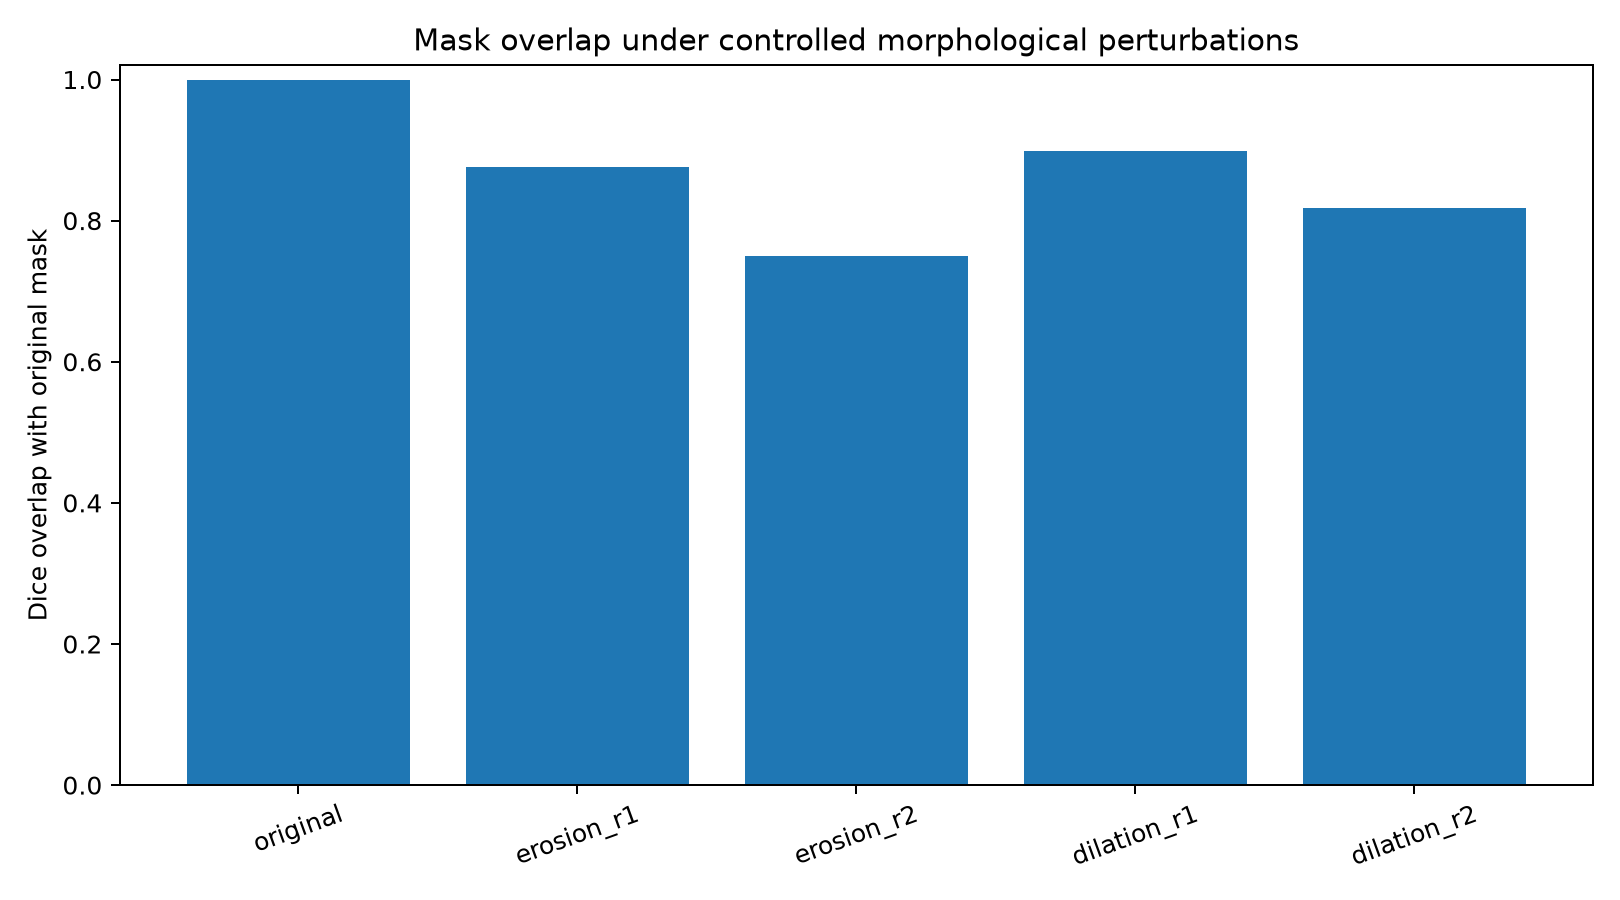

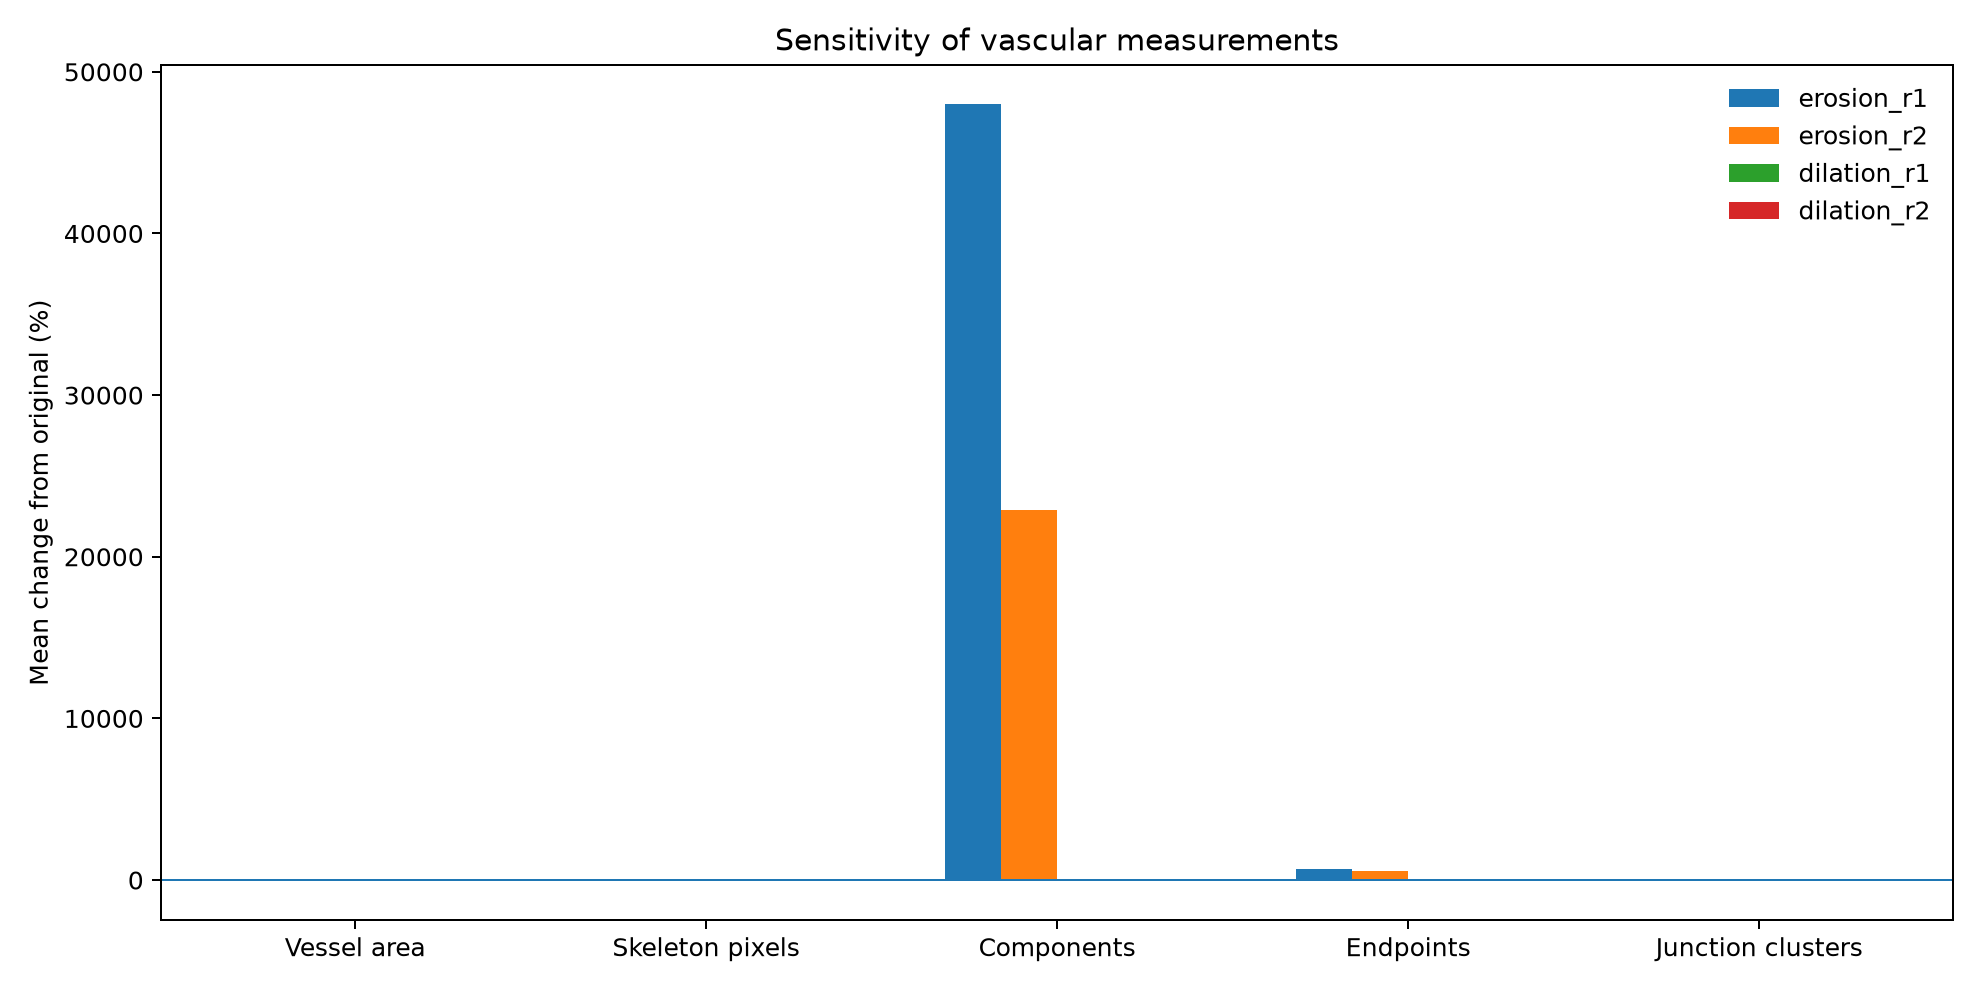

In [5]:
display(pd.read_csv(RESULTS / "per_image_features.csv").head())
display(pd.read_csv(RESULTS / "summary.csv"))

from IPython.display import Image, display
for figure in ("mask_overlap.png", "feature_sensitivity.png"):
    display(Image(filename=str(RESULTS / "figures" / figure)))